# Image Restoration
Target of this experiment is faithful image restoration, which we will progress in a staged progression and compare results.  Seleted stages are: classical image processing, Deep Learning approach , Real-world image Restoration.

Dataset: HuggingFace set14 (14 images) !https://huggingface.co/datasets/eugenesiow/Set14
Models: 
- Classical - bicubic https://opencv.org/resizing-and-rescaling-images-with-opencv
- Deep Learning - EDSR https://arxiv.org/abs/1707.02921


## Install Dependency

In [5]:
%pip install datasets pillow matplotlib
%pip install opencv-python numpy scikit-image

Note: you may need to restart the kernel to use updated packages.


## Step 1. Retrieve data

Loaded 14 image pairs
LR size: (125, 120)
HR size: (500, 480)


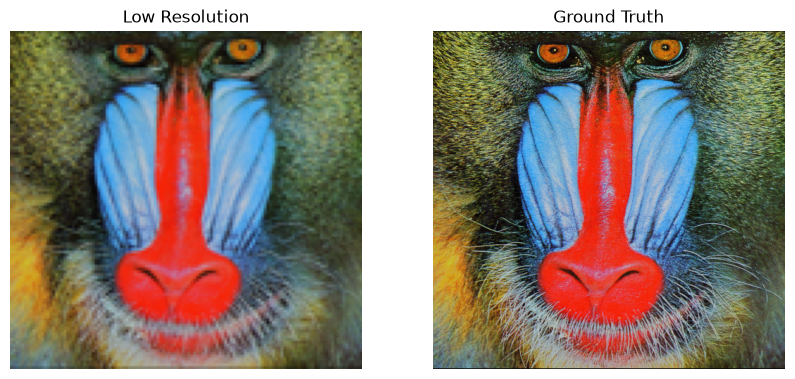

In [26]:
from pathlib import Path
import matplotlib.pyplot as plt
from urllib.request import urlretrieve
import tarfile
from PIL import Image

BASE_URL = (
    "https://huggingface.co/datasets/eugenesiow/"
    "Set14/resolve/main/data/"
)

# Data directory
root = Path("data/set14")
root.mkdir(parents=True, exist_ok=True)

archives = [
    "Set14_HR.tar.gz",
    "Set14_LR_x4.tar.gz"
]

# unarchive downloads
for filename in archives:
    target = root / filename

    if not target.exists():
        urlretrieve(BASE_URL + filename, target)

    with tarfile.open(target, "r:gz") as tar:
        tar.extractall(root, filter="data")

hr_dir = root / "Set14_HR"
lr_dir = root / "Set14_LR_x4"

pairs = []

for lr_path in sorted(lr_dir.glob("*.png")):
    hr_path = hr_dir / lr_path.name

    if hr_path.exists():
        pairs.append((lr_path, hr_path))

print(f"Loaded {len(pairs)} image pairs")

lr = Image.open(pairs[0][0]).convert("RGB")
hr = Image.open(pairs[0][1]).convert("RGB")

# low resolution image size and high resolution image size
print("LR size:", lr.size)
print("HR size:", hr.size)

# show image
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(lr)
axes[0].set_title("Low Resolution")

axes[1].imshow(hr)
axes[1].set_title("Ground Truth")

for ax in axes:
    ax.axis("off")

plt.show()

In [27]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

name = "comic.png"
scale = 4

root = Path("data/set14")
lr = cv2.imread(str(root / "Set14_LR_x4" / name))
hr = cv2.imread(str(root / "Set14_HR" / name))

assert lr is not None and hr is not None, "Image missing"

# Align HR with LR × 4
h, w = lr.shape[:2]
assert hr.shape[0] >= h * scale and hr.shape[1] >= w * scale
hr = hr[:h * scale, :w * scale]

print("LR:", lr.shape, "HR:", hr.shape)


LR: (90, 62, 3) HR: (360, 248, 3)


## Step 2. Classic Approach
OpenCV's bicubic

In [28]:
# Traditional CV - Cubic
traditional = cv2.resize(
    lr,
    (hr.shape[1], hr.shape[0]),
    interpolation=cv2.INTER_CUBIC
)

## Step 3 Deep Learning Approach

In [29]:
# Mordern CV - EDSR
assert hasattr(cv2, "dnn_superres"), (
    "Install opencv-contrib-python and restart Jupyter"
)

sr = cv2.dnn_superres.DnnSuperResImpl_create()
sr.readModel("models/EDSR_x4.pb")
sr.setModel("edsr", 4)

modern = sr.upsample(lr)

assert modern.shape == hr.shape

## Step 4 Result and Visualization

Bicubic  PSNR=19.15 dB SSIM=0.5583
EDSR     PSNR=19.35 dB SSIM=0.5807


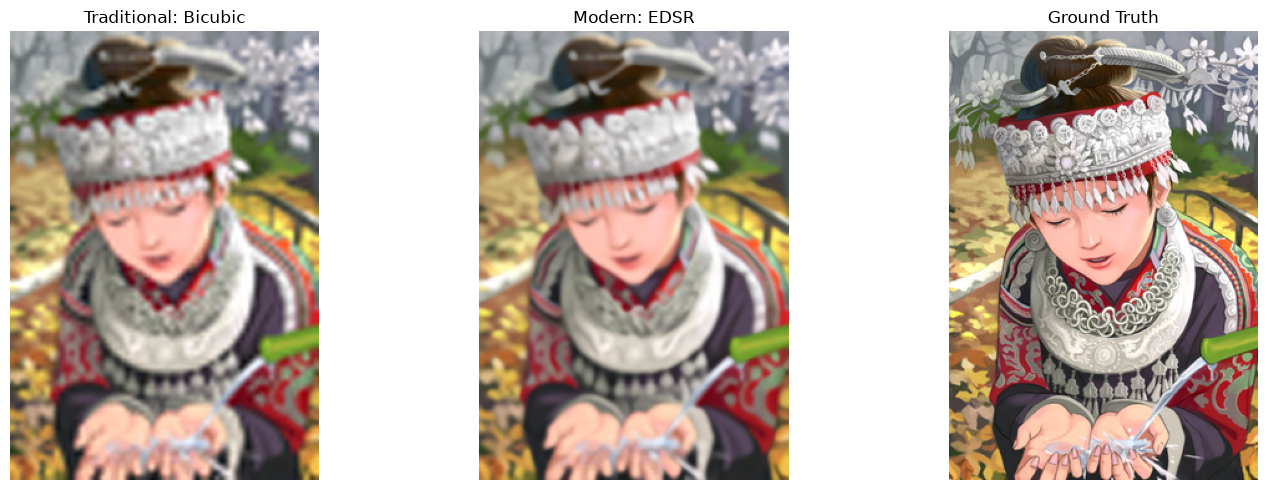

In [30]:
# Use a common 4-pixel border crop for fair evaluation
border = scale

def evaluate(output):
    ref = hr[border:-border, border:-border]
    pred = output[border:-border, border:-border]

    return {
        "PSNR": peak_signal_noise_ratio(ref, pred, data_range=255),
        "SSIM": structural_similarity(
            ref, pred, channel_axis=2, data_range=255
        )
    }

# Evaluate each model
for name, output in [
    ("Bicubic", traditional),
    ("EDSR", modern)
]:
    metrics = evaluate(output)
    print(f"{name:8} PSNR={metrics['PSNR']:.2f} dB "
          f"SSIM={metrics['SSIM']:.4f}")

# Identical display dimensions for all images
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, (title, image) in zip(axes, [
    ("Traditional: Bicubic", traditional),
    ("Modern: EDSR", modern),
    ("Ground Truth", hr)
]):
    ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

## Conclusion
From the result, EDSR outperforms Bicubic, but the improvement is modest. 
- Bicubic is usually preferred when speed, simplicity, and predictable behavior are priorities.
- EDSR is preferred when reconstruction quality matters more and the improvement is demonstrated on representative images.
**Ealuation Result**
- PSNR: EDSR produces slightly lower pixel-level reconstruction error.
- SSIM: EDSR better preserves structural information, including edges and textures.

## Limitations
- Only one image was evaluated. Results cannot be generalized to other images or datasets.
- Set14 LR images are generated through downsampling. Real photographs can contain noise, blur.. so the final result may be differnet
- Inference time, CPU/GPU utilization, and memory consumption were not measured in this experiment